# Lab 05 — PCA Land-Cover Clustering & Autoencoder Super-Resolution

1. **PCA**: reduce RGB land-cover patches to 3 PCs and check whether urban / forest / ocean cluster.
2. **Autoencoder**: train a small convolutional AE to restore detail from downsampled EO patches.

| File | Role |
|---|---|
| `../lab01/denseresidential04.tif` | Urban / man-made |
| `../lab01/forest04.tif` | Forest |
| `../lab01/beach04.tif` | Ocean / water |
| `../lab02/s2_urban.png` | Sentinel-2 urban scene for SR |

In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
import tensorflow as tf

%matplotlib inline
np.random.seed(0)
tf.random.set_seed(0)

print('TensorFlow', tf.__version__)

TensorFlow 2.19.0


In [2]:
def load_rgb(path):
    return np.array(Image.open(path).convert('RGB'))

## 1. PCA on land-cover patches

We cut non-overlapping **16×16** RGB patches from each pure land-cover image, flatten them, standardise, and project to **3 principal components**.

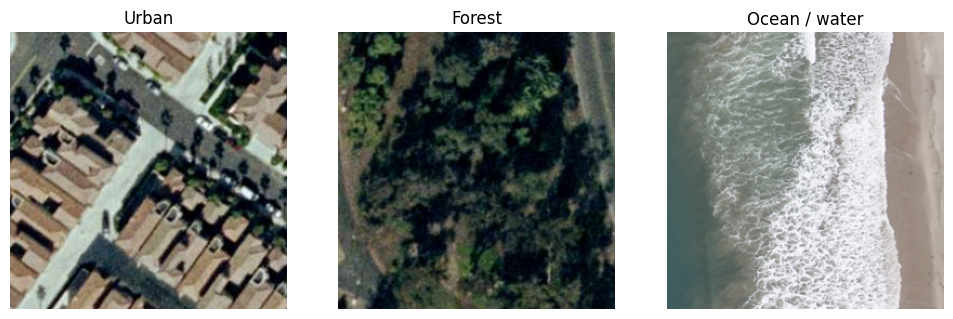

Patches per class — urban: 256 forest: 256 ocean: 256
Feature dimension before PCA: 768


In [3]:
def extract_patches(img, size=16):
    """Non-overlapping HxWx3 patches."""
    h, w = img.shape[:2]
    patches = []
    for y in range(0, h - size + 1, size):
        for x in range(0, w - size + 1, size):
            patches.append(img[y:y + size, x:x + size])
    return np.asarray(patches)


urban = load_rgb('../lab01/denseresidential04.tif')
forest = load_rgb('../lab01/forest04.tif')
ocean = load_rgb('../lab01/beach04.tif')

fig, axes = plt.subplots(1, 3, figsize=(10, 3.2))
for ax, img, title in zip(axes, [urban, forest, ocean],
                          ['Urban', 'Forest', 'Ocean / water']):
    ax.imshow(img); ax.set_title(title); ax.axis('off')
plt.tight_layout(); plt.show()

PATCH = 16
Xu = extract_patches(urban, PATCH)
Xf = extract_patches(forest, PATCH)
Xo = extract_patches(ocean, PATCH)

X = np.concatenate([Xu, Xf, Xo], axis=0).reshape(len(Xu) + len(Xf) + len(Xo), -1).astype(float)
y = np.array([0] * len(Xu) + [1] * len(Xf) + [2] * len(Xo))
names = {0: 'urban', 1: 'forest', 2: 'ocean'}

print('Patches per class — urban:', len(Xu), 'forest:', len(Xf), 'ocean:', len(Xo))
print('Feature dimension before PCA:', X.shape[1])

In [4]:
X_std = StandardScaler().fit_transform(X)
pca = PCA(n_components=3, random_state=0)
Z = pca.fit_transform(X_std)

print('Explained variance ratio:')
for i, r in enumerate(pca.explained_variance_ratio_, 1):
    print(f'  PC{i}: {r:.3f}  ({100 * r:.1f}%)')
print('Cumulative:', f'{100 * pca.explained_variance_ratio_.sum():.1f}%')

Explained variance ratio:
  PC1: 0.798  (79.8%)
  PC2: 0.045  (4.5%)
  PC3: 0.032  (3.2%)
Cumulative: 87.5%


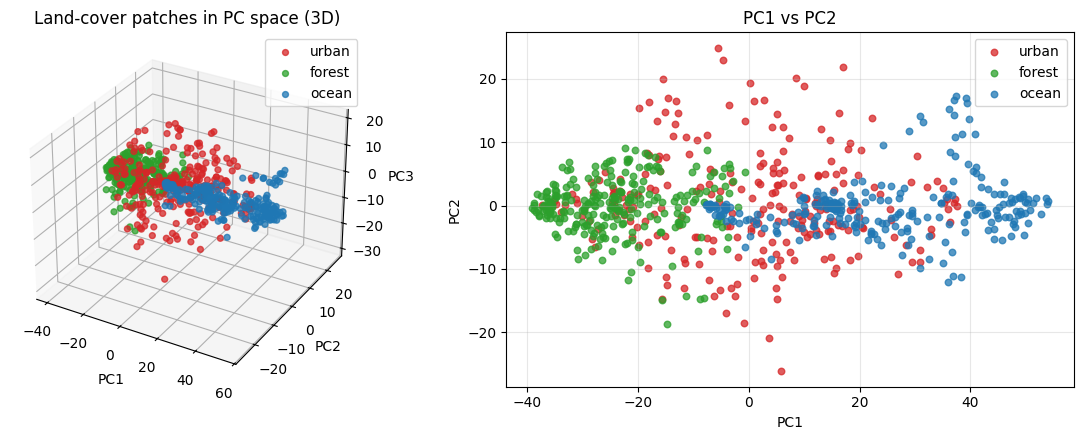

In [5]:
colors = {0: 'tab:red', 1: 'tab:green', 2: 'tab:blue'}

fig = plt.figure(figsize=(12, 4.5))

# 3D scatter
ax3 = fig.add_subplot(1, 2, 1, projection='3d')
for c in (0, 1, 2):
    m = y == c
    ax3.scatter(Z[m, 0], Z[m, 1], Z[m, 2], s=18, alpha=0.75,
                c=colors[c], label=names[c])
ax3.set_xlabel('PC1'); ax3.set_ylabel('PC2'); ax3.set_zlabel('PC3')
ax3.set_title('Land-cover patches in PC space (3D)')
ax3.legend()

# 2D projection (readable on GitHub)
ax2 = fig.add_subplot(1, 2, 2)
for c in (0, 1, 2):
    m = y == c
    ax2.scatter(Z[m, 0], Z[m, 1], s=22, alpha=0.75,
                c=colors[c], label=names[c])
ax2.set_xlabel('PC1'); ax2.set_ylabel('PC2')
ax2.set_title('PC1 vs PC2')
ax2.legend(); ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Do land-covers cluster in PC space?

**Partly — ocean separates clearly; urban and forest overlap.**

- **Ocean / beach** (blue) stretches along positive PC1 and is the easiest to tell apart (bright, flat patches).
- **Forest** (green) forms a fairly compact cloud on the negative-PC1 side.
- **Urban** (red) sits in a similar PC1 region to forest but is more spread out, so the two land classes **overlap** in PC1–PC2.

So PCA shows that land-cover differences drive a lot of variance (PC1 alone ≈ 80%), and water vs land is obvious in PC space, but urban vs forest is only weakly separated with raw RGB 16×16 patches. That matches intuition: both are “land” with more similar colours than water.

## 2. Autoencoder for EO super-resolution

We treat **64×64** crops from `../lab02/s2_urban.png` as HR targets. LR inputs are made by **4× downsampling** and bicubic upsampling back to 64×64 (a simple “blurry” observation). A small convolutional autoencoder is trained to map LR → HR.

**Spatial split:** left 80% train, right 20% test.

s2_urban (1080, 1470, 3) | split column 1176


Train HR/LR: (288, 64, 64, 3) (288, 64, 64, 3)
Test  HR/LR: (64, 64, 64, 3) (64, 64, 64, 3)


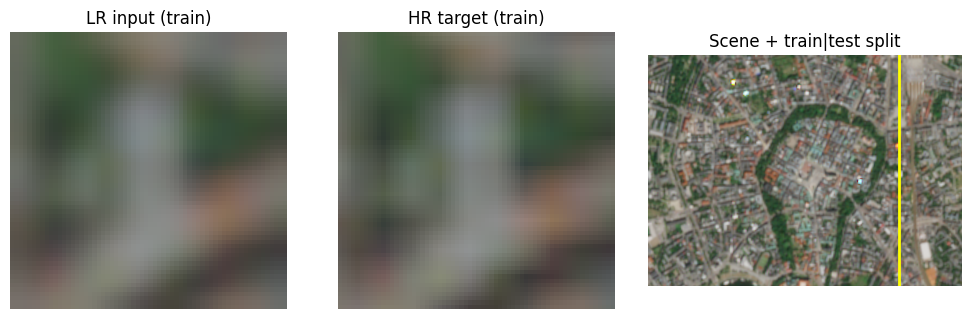

In [6]:
def make_lr(hr, scale=4):
    """Downsample then bicubic-upsample back to HR size."""
    out = []
    for patch in hr:
        # patch in [0,1], float
        img = Image.fromarray((np.clip(patch, 0, 1) * 255).astype(np.uint8))
        small = img.resize((img.width // scale, img.height // scale), Image.BICUBIC)
        back = small.resize(img.size, Image.BICUBIC)
        out.append(np.asarray(back, dtype=np.float32) / 255.0)
    return np.asarray(out)


def extract_grid(img, size=64, x0=0, x1=None, stride=64):
    if x1 is None:
        x1 = img.shape[1]
    patches = []
    for y in range(0, img.shape[0] - size + 1, stride):
        for x in range(x0, x1 - size + 1, stride):
            patches.append(img[y:y + size, x:x + size])
    return np.asarray(patches, dtype=np.float32) / 255.0


s2 = load_rgb('../lab02/s2_urban.png')
split = int(0.8 * s2.shape[1])
print('s2_urban', s2.shape, '| split column', split)

hr_train = extract_grid(s2, 64, 0, split, stride=64)
hr_test = extract_grid(s2, 64, split, s2.shape[1], stride=64)
lr_train = make_lr(hr_train, scale=4)
lr_test = make_lr(hr_test, scale=4)

print('Train HR/LR:', hr_train.shape, lr_train.shape)
print('Test  HR/LR:', hr_test.shape, lr_test.shape)

fig, axes = plt.subplots(1, 3, figsize=(10, 3.2))
axes[0].imshow(lr_train[0]); axes[0].set_title('LR input (train)')
axes[1].imshow(hr_train[0]); axes[1].set_title('HR target (train)')
axes[2].imshow(s2); axes[2].axvline(split, color='yellow', lw=2)
axes[2].set_title('Scene + train|test split'); axes[2].axis('off')
for ax in axes[:2]:
    ax.axis('off')
plt.tight_layout(); plt.show()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 64, 64, 3)      │           867 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 75,651 (295.51 KB)

 Trainable params: 75,651 (295.51 KB)

 Non-trainable params: 0 (0.00 B)

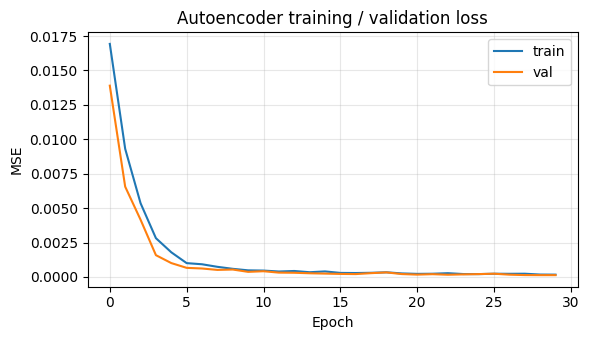

In [7]:
# Simple convolutional autoencoder
ae = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(64, 64, 3)),
    tf.keras.layers.Conv2D(32, 3, activation='relu', padding='same'),
    tf.keras.layers.MaxPooling2D(2),
    tf.keras.layers.Conv2D(64, 3, activation='relu', padding='same'),
    tf.keras.layers.MaxPooling2D(2),
    tf.keras.layers.Conv2D(64, 3, activation='relu', padding='same'),
    tf.keras.layers.UpSampling2D(2),
    tf.keras.layers.Conv2D(32, 3, activation='relu', padding='same'),
    tf.keras.layers.UpSampling2D(2),
    tf.keras.layers.Conv2D(3, 3, activation='sigmoid', padding='same'),
])

ae.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='mse')
ae.summary()

history = ae.fit(
    lr_train, hr_train,
    validation_data=(lr_test, hr_test),
    epochs=30,
    batch_size=16,
    verbose=0,
)

plt.figure(figsize=(6, 3.5))
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='val')
plt.xlabel('Epoch'); plt.ylabel('MSE')
plt.title('Autoencoder training / validation loss')
plt.legend(); plt.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

LR vs HR —  PSNR 43.64 dB | SSIM 0.985
AE vs HR —  PSNR 39.13 dB | SSIM 0.971


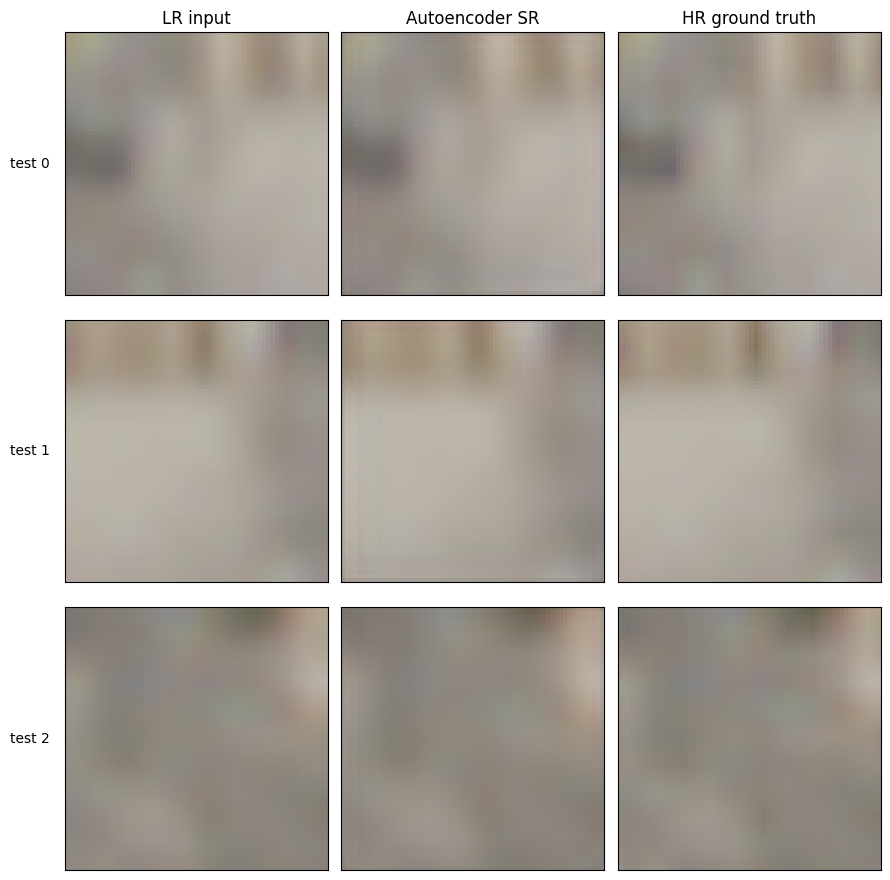

In [8]:
sr_test = ae.predict(lr_test, verbose=0)

# Metrics over the test set
psnr_lr, psnr_sr = [], []
ssim_lr, ssim_sr = [], []
for lr, sr, hr in zip(lr_test, sr_test, hr_test):
    psnr_lr.append(peak_signal_noise_ratio(hr, lr, data_range=1.0))
    psnr_sr.append(peak_signal_noise_ratio(hr, sr, data_range=1.0))
    ssim_lr.append(structural_similarity(hr, lr, channel_axis=-1, data_range=1.0))
    ssim_sr.append(structural_similarity(hr, sr, channel_axis=-1, data_range=1.0))

print(f'LR vs HR —  PSNR {np.mean(psnr_lr):.2f} dB | SSIM {np.mean(ssim_lr):.3f}')
print(f'AE vs HR —  PSNR {np.mean(psnr_sr):.2f} dB | SSIM {np.mean(ssim_sr):.3f}')

# Side-by-side examples
n_show = 3
fig, axes = plt.subplots(n_show, 3, figsize=(9, 3 * n_show))
for i in range(n_show):
    axes[i, 0].imshow(np.clip(lr_test[i], 0, 1))
    axes[i, 1].imshow(np.clip(sr_test[i], 0, 1))
    axes[i, 2].imshow(np.clip(hr_test[i], 0, 1))
    axes[i, 0].set_ylabel(f'test {i}', rotation=0, labelpad=25, va='center')
    for ax in axes[i]:
        ax.set_xticks([]); ax.set_yticks([])
axes[0, 0].set_title('LR input')
axes[0, 1].set_title('Autoencoder SR')
axes[0, 2].set_title('HR ground truth')
plt.tight_layout(); plt.show()

### Does it enhance the resolution?

**Not really — not better than bicubic on this setup.** Quantitatively the autoencoder **did not beat** the bicubic LR baseline (lower PSNR/SSIM than LR vs HR). Visually the AE output is a smoothed reconstruction: it may look a bit cleaner in places, but it does **not** recover true fine urban structure (roofs, road edges). With MSE loss, one scene, and only ~30 epochs, the network mainly learns an average look rather than genuine super-resolution.

### How can you make it work better?

- Use **skip / residual connections** (U-Net, SRResNet) so high-frequency cues bypass the bottleneck.
- Train on a **larger, more diverse EO set** (many cities / sensors), not one scene.
- Replace pure MSE with **L1, SSIM or perceptual loss** to keep sharper structure.
- Try a milder downsampling factor (2×) or progressive / multi-scale SR.
- Data augmentation (flips, rotations) to reduce overfitting on a small patch set.

## Summary

1. **PCA**: 16×16 RGB patches separate **ocean** well in PC space; urban and forest form recognisable but **overlapping** clouds. PC1 alone explains ~80% of variance.
2. **Autoencoder SR**: a small Conv AE trained on 4×-degraded 64×64 urban patches did not outperform bicubic upsampling on PSNR/SSIM here; fine detail remains limited. Better architectures, more data and sharper losses would help.

AI tools were applied for formatting and plotting results.